In [1]:
import tensorflow as tf 
from sklearn.preprocessing import LabelEncoder,StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,f1_score

In [2]:
data=pd.read_csv("fashion-mnist_train.csv")
data.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
data.shape

(60000, 785)

In [4]:
X=data.drop('label',axis=1)
y=data.label

In [5]:
sc=StandardScaler()
X=sc.fit_transform(X)

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y)


# parameters

In [7]:
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
initialization=tf.keras.initializers.GlorotUniform(seed=42)
regularization=tf.keras.regularizers.L2(l2=.02)


In [8]:
# with tf.device('/device:DML:0'):
model=tf.keras.Sequential([
            tf.keras.Input(shape=(X_train.shape[1],)),
    
            tf.keras.layers.Dense(
                800,
                kernel_initializer= initialization,
                kernel_regularizer=regularization                     
            ),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Activation(activation='relu'),
            tf.keras.layers.Dropout(rate=.4, seed=42),
            
    
            tf.keras.layers.Dense(
                400,
                kernel_initializer=initialization,
                kernel_regularizer=regularization
            ),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Activation(activation='relu'),
            tf.keras.layers.Dropout(rate=.3,seed=42),
    
    
               tf.keras.layers.Dense(
                200,
                kernel_initializer=initialization,
                kernel_regularizer=regularization
            ),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Activation(activation='relu'),
            tf.keras.layers.Dropout(rate=.2,seed=42),
    
               tf.keras.layers.Dense(
                100,
                kernel_initializer=initialization,
                kernel_regularizer=regularization
            ),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Activation(activation='relu'),
            tf.keras.layers.Dropout(rate=.1,seed=42),
    
            tf.keras.layers.Dense(
                10,
                kernel_initializer=initialization
            )        
        ]
            
        )


In [9]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 800)               628000    
                                                                 
 batch_normalization (BatchN  (None, 800)              3200      
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 800)               0         
                                                                 
 dropout (Dropout)           (None, 800)               0         
                                                                 
 dense_1 (Dense)             (None, 400)               320400    
                                                                 
 batch_normalization_1 (Batc  (None, 400)              1600      
 hNormalization)                                        

In [10]:
# with tf.device('/device:DML:0'):
model.compile(
optimizer=optimizer,
loss=loss_fn,
metrics=['accuracy']
  )

In [11]:
# with tf.device('/device:DML:0'):
history=model.fit(X_train,y_train,
        validation_data=[X_test,y_test],
        epochs=20,
        batch_size=512 )
    

Epoch 1/20
94/94 [==============================] - 8s 62ms/step - loss: 11.5817 - accuracy: 0.7525 - val_loss: 3.3295 - val_accuracy: 0.3980
Epoch 2/20
94/94 [==============================] - 5s 56ms/step - loss: 1.2223 - accuracy: 0.8151 - val_loss: 2.0575 - val_accuracy: 0.6855
Epoch 3/20
94/94 [==============================] - 5s 56ms/step - loss: 0.8946 - accuracy: 0.8149 - val_loss: 1.3799 - val_accuracy: 0.8133
Epoch 4/20
94/94 [==============================] - 5s 56ms/step - loss: 0.8574 - accuracy: 0.8174 - val_loss: 0.9883 - val_accuracy: 0.8021
Epoch 5/20
94/94 [==============================] - 5s 56ms/step - loss: 0.8535 - accuracy: 0.8176 - val_loss: 0.8990 - val_accuracy: 0.8263
Epoch 6/20
94/94 [==============================] - 5s 56ms/step - loss: 0.8469 - accuracy: 0.8156 - val_loss: 0.9420 - val_accuracy: 0.7900
Epoch 7/20
94/94 [==============================] - 5s 56ms/step - loss: 0.8579 - accuracy: 0.8164 - val_loss: 0.8050 - val_accuracy: 0.8368
Epoch 8/20
9

In [12]:
loss_df=pd.DataFrame(history.history)
loss_df

,loss,accuracy,val_loss,val_accuracy
0,11.581690,0.752521,3.329524,0.398000
1,1.222262,0.815146,2.057478,0.685500
2,0.894559,0.814917,1.379929,0.813250
3,0.857416,0.817417,0.988325,0.802083
4,0.853542,0.817604,0.898952,0.826333
5,0.846917,0.815583,0.941974,0.790000
6,0.857942,0.816375,0.805021,0.836833
7,0.849345,0.815042,0.847473,0.814917
8,0.854133,0.816208,0.815775,0.834167
9,0.847924,0.817021,0.811587,0.833167


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import ListedColormap

def fn_plot_tf_hist(hist_df):
    """
    Plots training history with side-by-side Loss and Accuracy curves.
    Automatically highlights the best epoch based on minimum validation loss.
    """
    # 1. Create the figure and axes layout
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Custom colormap: Blue for training, Red/Crimson for validation
    CMAP = ListedColormap(['#3F51B5', '#D32F2F'])
    
    # 2. Get columns by index to eliminate any column naming errors
    # Expected positions: y1=accuracy, y2=loss, y3=val_accuracy, y4=val_loss
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # 3. Find the best epoch details based on minimum validation loss
    min_loss_row = hist_df[hist_df[y4] == hist_df[y4].min()]
    best_epoch = min_loss_row.index[0]
    min_loss = min_loss_row[y4].values[0]
    best_acc = min_loss_row[y3].values[0]

    # ==========================================
    # LEFT PLOT: LOSS CURVE
    # ==========================================
    ax0 = axes[0]
    hist_df.plot(y=[y2, y4], ax=ax0, colormap=CMAP)
    
    # Layout and Labels
    ax0.set_title("Loss Curve", fontsize=12)
    ax0.set_xlabel("Epochs")
    ax0.set_ylabel("Loss")
    ax0.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax0.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch loss metrics (top left)
    txtFmt_loss = "Loss:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_loss = txtFmt_loss.format(hist_df.iloc[-1][y2], hist_df.iloc[-1][y4])
    ax0.text(0.2, 0.85, txtstr_loss, transform=ax0.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to the minimum validation loss
    ax0.annotate(f'Min: {min_loss:.4f}', 
                 xy=(best_epoch, min_loss), 
                 xytext=(-60, 45),            # Fixed pixel offset to the left and up
                 textcoords='offset points',  # Prevents squishing on different data scales
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='bottom')

    # ==========================================
    # RIGHT PLOT: ACCURACY CURVE
    # ==========================================
    ax1 = axes[1]
    hist_df.plot(y=[y1, y3], ax=ax1, colormap=CMAP)
    
    # Layout and Labels
    ax1.set_title("Accuracy Curve", fontsize=12)
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.grid(True, alpha=0.3)
    
    # Green dash-dot vertical line at the best epoch
    ax1.axvline(x=best_epoch, color='g', linestyle='-.', linewidth=2)
    
    # Text box for final epoch accuracy metrics (bottom center)
    txtFmt_acc = "Accuracy:\n train: {:6.4f}\n  test: {:6.4f}"
    txtstr_acc = txtFmt_acc.format(hist_df.iloc[-1][y1], hist_df.iloc[-1][y3])
    ax1.text(0.3, 0.15, txtstr_acc, transform=ax1.transAxes, fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="cyan", alpha=0.2, edgecolor="grey"))
    
    # Robust annotation pointing to accuracy at the best epoch
    ax1.annotate(f'Best: {best_acc:.4f}', 
                 xy=(best_epoch, best_acc), 
                 xytext=(-60, -35),           # Fixed pixel offset to the left and down
                 textcoords='offset points',  # Prevents squishing when accuracy hugs 1.0
                 arrowprops=dict(facecolor='cyan', shrink=0.1, width=2, headwidth=8),
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="cyan", alpha=0.2, edgecolor="grey"),
                 ha='right', va='top')

    # Final rendering tweaks
    plt.tight_layout()
    plt.show()


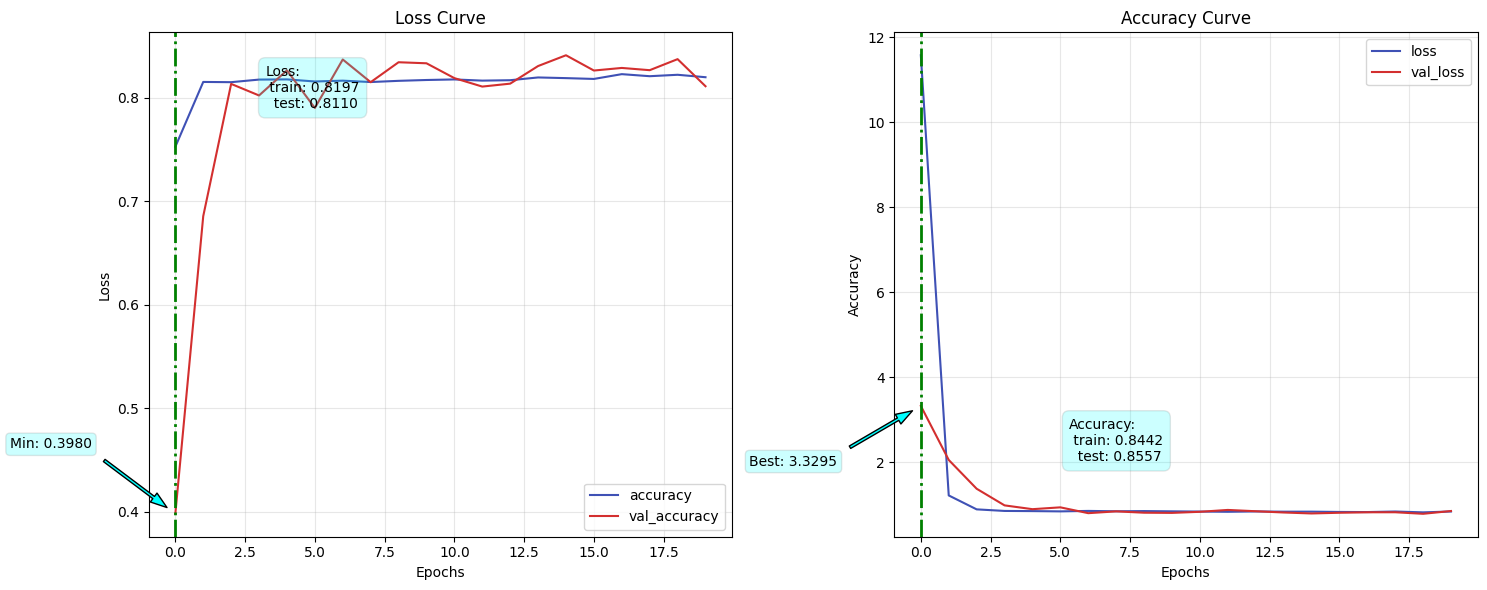

In [14]:
fn_plot_tf_hist(loss_df)